студент приходит в вуз, в вузе нет света, он выбирает в темноте наугад дверь. после этого видит, как в одну из двух невыбранных заходит его одногруппник и тут же выходит. Он сделал неправильный выбор и ждет твоего хода. Стоит ли с точки зрения вероятности менять выбор?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def simulate_university_search(switch=True):
    # Случайный выбор правильной аудитории (от 0 до 2)
    target_room = np.random.randint(0, 3)
    # Первоначальный выбор студента в темноте
    student_choice = np.random.randint(0, 3)
    
    if switch:
        # При смене двери студент выигрывает, если изначально выбрал не ту дверь
        return student_choice != target_room
    else:
        # При сохранении выбора — если сразу угадал
        return student_choice == target_room

# Проверка нескольких тестовых попыток
for i in range(5):
    res_stay = simulate_university_search(False)
    res_switch = simulate_university_search(True)
    print(f"Попытка {i + 1} | Без смены: {res_stay} | Со сменой: {res_switch}")

# Моделирование 10 000 поисков для обеих стратегий
n_iterations = 10000
targets = np.random.randint(0, 3, size=n_iterations)
choices = np.random.randint(0, 3, size=n_iterations)

strat_stay = (choices == targets)
strat_switch = (choices != targets)

win_stay = np.mean(strat_stay)
win_switch = np.mean(strat_switch)

print(f"\nРезультаты после {n_iterations} симуляций:")
print(f"Доля успеха без смены двери: {win_stay:.4f}")
print(f"Доля успеха при смене двери:  {win_switch:.4f}")

# Сводная таблица результатов
df_results = pd.DataFrame({
    'Стратегия студента': ['Не менять дверь', 'Сменить дверь'],
    'Теоретическая вероятность': [1/3, 2/3],
    'Частота в симуляции': [win_stay, win_switch]
})
display(df_results)


Попытка 1 | Без смены: False | Со сменой: False
Попытка 2 | Без смены: False | Со сменой: True
Попытка 3 | Без смены: False | Со сменой: True
Попытка 4 | Без смены: False | Со сменой: False
Попытка 5 | Без смены: False | Со сменой: True

Результаты после 10000 симуляций:
Доля успеха без смены двери: 0.3321
Доля успеха при смене двери:  0.6679


,Стратегия студента,Теоретическая вероятность,Частота в симуляции
0,Не менять дверь,0.333333,0.3321
1,Сменить дверь,0.666667,0.6679


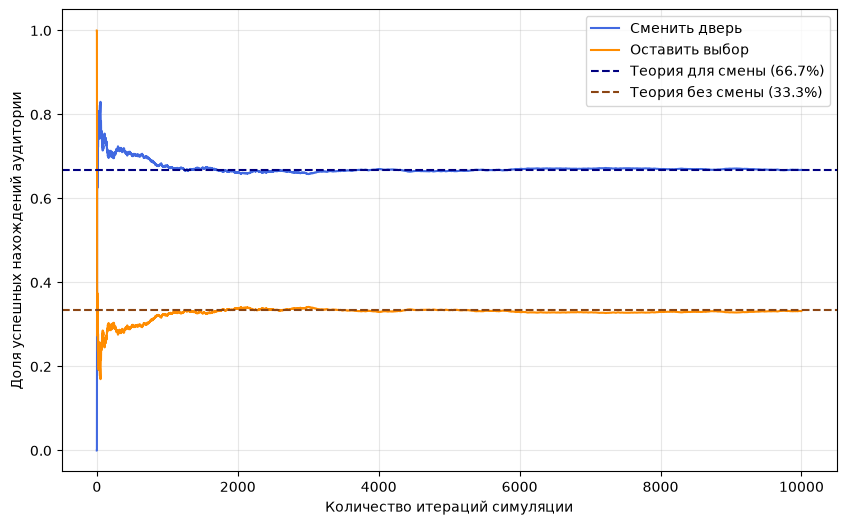

In [2]:

# Построение графика сходимости относительной частоты побед
cum_stay = np.cumsum(strat_stay) / np.arange(1, n_iterations + 1)
cum_switch = np.cumsum(strat_switch) / np.arange(1, n_iterations + 1)

plt.figure(figsize=(10, 6))
plt.plot(cum_switch, label='Сменить дверь', color='royalblue')
plt.plot(cum_stay, label='Оставить выбор', color='darkorange')
plt.axhline(2/3, color='navy', linestyle='--', label='Теория для смены (66.7%)')
plt.axhline(1/3, color='saddlebrown', linestyle='--', label='Теория без смены (33.3%)')
plt.xlabel('Количество итераций симуляции')
plt.ylabel('Доля успешных нахождений аудитории')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()